<a href="https://colab.research.google.com/github/hanifsyahrulramadhan424-blip/Klasifikasi-Status-Akademik-Random-Forest/blob/main/Klasifikasi_Status_Akademik_Random_Forest_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="border-left:6px solid #198580;padding:22px 26px;background:#f1f6f7;color:#173443;">
<p style="font-size:12px;letter-spacing:2px;margin:0 0 12px;">TUGAS MACHINE LEARNING · KLASIFIKASI</p>
<h1 style="font-size:29px;line-height:1.3;margin:0 0 8px;">Klasifikasi Status Akademik Mahasiswa</h1>
<p style="font-size:18px;margin:0;">Menggunakan Algoritma Random Forest</p>
</div>

| Identitas | Keterangan |
|:---|:---|
| Nama | [Hanif Syahrul Ramadhan] |
| NIM | [2404010004] |
| Program Studi | [Statistika Terapan dan Komputasi] |

**Studi kasus:** mengklasifikasikan status mahasiswa menjadi **Dropout**, **Enrolled**, atau **Graduate**.

Notebook memuat penjelasan, kode Python, dan hasil eksekusi. Angka evaluasi berasal dari
perhitungan pada dataset, bukan hasil yang disalin dari artikel.

**Petunjuk:** isi identitas, lalu pilih **Runtime → Run all**. Gunakan Python dengan CPU;
GPU tidak diperlukan. Unduhan dataset memerlukan internet. Daftar isi pada panel kiri
Colab dapat digunakan untuk berpindah bagian.

---

**Susunan laporan**

1. Pendahuluan — permasalahan dan tujuan
2. Dataset — sumber, target, dan cakupan
3. Metode — Random Forest
4. Tahapan penerapan — persiapan sampai pelatihan
5. Hasil dan pembahasan — metrik, kesalahan, dan contoh prediksi
6. Manfaat, keterbatasan, dan kesimpulan
7. Daftar referensi


## 1. Pendahuluan

Perguruan tinggi perlu menentukan mahasiswa yang memerlukan pendampingan akademik.
Pemeriksaan banyak indikator secara manual dapat menyulitkan penentuan prioritas.
Contoh penerapan dalam tugas ini adalah mempelajari hubungan antara karakteristik mahasiswa
dan status akademiknya, kemudian mengklasifikasikan mahasiswa ke dalam tiga kategori.

Artikel Realinho dkk. (2022) menjelaskan penggunaan dataset ini dalam alat analitik pembelajaran
untuk membantu tim pendamping memperkirakan risiko kegagalan dan putus studi [2].
Notebook ini merupakan eksperimen pembelajaran tersendiri, bukan reproduksi persis model artikel.

**Rumusan masalah:** seberapa baik Random Forest memprediksi `Dropout`, `Enrolled`, dan `Graduate`
pada data uji yang tidak digunakan untuk melatih model?

**Tujuan:** membangun model, membandingkannya dengan tebakan kelas mayoritas, serta
menelaah kesalahan pada setiap kelas. Hasil prediksi dimaksudkan sebagai bahan pendampingan,
bukan keputusan otomatis mengenai kelulusan mahasiswa.

## 2. Dataset

Dataset: **Predict Students’ Dropout and Academic Success**, tersedia di
[UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) [1].
Sumber penelitian: Instituto Politécnico de Portalegre, Portugal [2].
File yang digunakan berisi **4.424 baris, 36 fitur, dan satu kolom target**.
UCI merupakan repositori distribusi dataset penelitian ini.

| Target | Arti |
|---|---|
| Dropout | Keluar/putus studi menurut definisi penelitian |
| Enrolled | Masih terdaftar pada akhir durasi normal program |
| Graduate | Lulus |

Definisi dropout dalam penelitian asal juga mencakup pindah program atau institusi [2].
Enrolled tidak boleh disamakan dengan dropout. Berkas yang diunduh menjadi acuan jumlah
kolom pada eksperimen ini, meskipun artikel menyebut jumlah atribut yang berbeda.

**Cakupan eksperimen:** menggunakan seluruh fitur yang dirilis, termasuk informasi
semester 1–2. Ini bukan prediksi saat pendaftaran. Data tidak memuat tanggal kejadian
dropout maupun waktu pembaruan tiap status administratif. Karena itu, eksperimen ini
tidak membuktikan kemampuan prediksi prospektif pada satu tanggal tertentu; penerapan
nyata memerlukan audit waktu ketersediaan fitur.

## 3. Metode Klasifikasi

Random Forest melatih banyak pohon keputusan menggunakan sampel bootstrap dan pemilihan
fitur acak. Implementasi scikit-learn merata-ratakan probabilitas kelas dari pohon-pohon,
lalu memilih kelas dengan probabilitas rata-rata tertinggi [3].

Metode ini dipilih untuk mencoba pola nonlinier dan interaksi antarvariabel pada data tabel.
Pemilihannya tidak berarti bahwa Random Forest pasti menjadi algoritma terbaik.
Eksperimen menetapkan 200 pohon, kedalaman maksimum 12, minimum 2 observasi per daun,
dan bobot kelas `balanced`. Bobot membantu memperhitungkan ketimpangan kelas, tetapi tidak
menjamin peningkatan kinerja. Parameter ditetapkan sebelum evaluasi data uji.

Kode kategori nominal diubah dengan **one-hot encoding**. Fitur numerik tidak distandardisasi
karena model pohon tidak memerlukannya. Semua transformasi yang belajar dari data ditempatkan
dalam pipeline dan hanya dipasang pada data latih [4].

## 4. Tahapan Penerapan

### 4.1 Persiapan Pustaka
Pustaka berikut umumnya tersedia di Colab. Jika muncul `ModuleNotFoundError`, jalankan
`%pip install pandas numpy matplotlib scikit-learn` pada sel baru, kemudian jalankan ulang.
Versi dicatat agar hasil dapat ditelusuri; perubahan versi dapat menimbulkan perbedaan kecil.

In [ ]:
import io
import zipfile
import urllib.request
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown, HTML
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
LABELS = ['Dropout', 'Enrolled', 'Graduate']
pd.set_option('display.max_columns', 12)
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 10, 'axes.titlesize': 13,
    'axes.titleweight': 'bold', 'axes.titlepad': 16,
    'axes.labelcolor': '#284454', 'text.color': '#173443',
    'xtick.color': '#284454', 'ytick.color': '#284454',
    'axes.spines.top': False, 'axes.spines.right': False
})
print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| scikit-learn:', sklearn.__version__)


def show_table(frame, title, formats=None, collapsible=False):
    """Tampilkan tabel HTML tanpa pustaka pemformatan tambahan."""
    from html import escape
    formats = formats or {}
    th_style = 'background:#173f50;color:white;padding:11px 14px;text-align:left;font-size:13px;'
    td_style = 'padding:10px 14px;border-bottom:1px solid #e3ebee;color:#203e4d;font-size:13px;'
    table = '<table style="border-collapse:collapse;font-family:Arial,sans-serif;">'
    table += '<tr>' + ''.join('<th style="' + th_style + '">' + escape(str(col)) + '</th>' for col in frame.columns) + '</tr>'
    for row_index, row in enumerate(frame.itertuples(index=False, name=None)):
        color = '#ffffff' if row_index % 2 == 0 else '#f2f7f8'
        table += '<tr style="background:' + color + ';">'
        for col, value in zip(frame.columns, row):
            shown = formats[col].format(value) if col in formats else str(value)
            table += '<td style="' + td_style + '">' + escape(shown) + '</td>'
        table += '</tr>'
    table += '</table>'
    html = '<div style="overflow-x:auto;margin:12px 0 20px;">' + table + '</div>'
    heading = '<p style="font:600 14px Arial;color:#173f50;margin:18px 0 6px;">' + escape(title) + '</p>'
    if collapsible:
        html = '<details><summary style="cursor:pointer;padding:12px;color:#173f50;">' + escape(title) + '</summary>' + html + '</details>'
        display(HTML(html))
    else:
        display(HTML(heading + html))


Python: 3.12.14
pandas: 2.2.3 | numpy: 2.3.5 | scikit-learn: 1.8.0


### 4.2 Pengambilan Dataset
CSV menggunakan pemisah titik koma (`;`). Sel ini mengunduh ZIP resmi dan membaca CSV di
dalamnya tanpa memerlukan Google Drive. Jika layanan UCI sedang tidak tersedia, unduh ZIP
dari halaman dataset dan unggah ke Colab; isi `LOCAL_ZIP` dengan lokasi file tersebut.

In [ ]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip'
LOCAL_ZIP = None  # Contoh jika unggah manual: '/content/nama_dataset.zip'
if LOCAL_ZIP:
    with open(LOCAL_ZIP, 'rb') as f:
        raw_zip = f.read()
else:
    with urllib.request.urlopen(DATA_URL, timeout=60) as response:
        raw_zip = response.read()

with zipfile.ZipFile(io.BytesIO(raw_zip)) as archive:
    csv_name = next(name for name in archive.namelist() if name.endswith('data.csv'))
    csv_bytes = archive.read(csv_name)
    df_raw = pd.read_csv(io.BytesIO(csv_bytes), sep=';')

print('Sumber:', DATA_URL)
print('SHA-256 CSV:', hashlib.sha256(csv_bytes).hexdigest())
print('Ukuran:', df_raw.shape)
preview_cols = ['Age at enrollment', 'Admission grade', 'Scholarship holder',
                'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)', 'Target']
preview = df_raw[preview_cols].head().rename(columns={
    'Age at enrollment': 'Usia masuk', 'Admission grade': 'Nilai masuk',
    'Scholarship holder': 'Beasiswa (kode)', 'Curricular units 1st sem (grade)': 'Nilai semester 1',
    'Curricular units 2nd sem (grade)': 'Nilai semester 2', 'Target': 'Status'
})
show_table(preview, 'Tabel 1. Lima baris pertama — kolom pilihan',
           {'Nilai masuk': '{:.2f}', 'Nilai semester 1': '{:.2f}', 'Nilai semester 2': '{:.2f}'})

Sumber: https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip
SHA-256 CSV: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae
Ukuran: (4424, 37)


Usia masuk,Nilai masuk,Beasiswa (kode),Nilai semester 1,Nilai semester 2,Status
20,127.30,0,0.00,0.00,Dropout
19,142.50,0,14.00,13.67,Graduate
19,124.80,0,0.00,0.00,Dropout
20,119.60,0,13.43,12.40,Graduate
45,141.50,0,12.33,13.00,Graduate


### 4.3 Pemeriksaan dan Pembersihan Data
Kita memeriksa nilai kosong, duplikasi, dan label sebelum pemodelan. Nilai nol tidak
otomatis dianggap hilang: pada indikator tertentu nol mempunyai arti yang sah.
Nama kolom dirapikan karena ada karakter tab di akhir satu nama kolom.

In [ ]:
df = df_raw.copy()
df.columns = df.columns.str.strip()
df['Target'] = df['Target'].astype('string').str.strip()
audit = pd.DataFrame({
    'Pemeriksaan': ['Jumlah baris', 'Jumlah fitur', 'Nilai kosong',
                   'Baris duplikat identik', 'Target kosong', 'Nilai numerik tak hingga'],
    'Hasil': [len(df), df.shape[1]-1, int(df.isna().sum().sum()),
              int(df.duplicated().sum()), int(df['Target'].isna().sum() + df['Target'].eq('').sum()),
              int(np.isinf(df.select_dtypes('number')).sum().sum())]
})
show_table(audit, 'Tabel 2. Hasil pemeriksaan struktur data')
assert not df.isna().any().any(), 'Ada nilai kosong: perlu penanganan sebelum melanjutkan.'
assert set(df['Target']) == set(LABELS), 'Label tidak sesuai dokumentasi.'
assert np.isfinite(df.select_dtypes('number').to_numpy()).all()
df = df.drop_duplicates().reset_index(drop=True)

# Kode 34 = Unknown pada pendidikan orang tua, bukan nilai pendidikan 34.
unknown_counts = pd.DataFrame({
    'Variabel': ["Mother's qualification", "Father's qualification"],
    'Jumlah tidak diketahui': [int(df["Mother's qualification"].eq(34).sum()),
                               int(df["Father's qualification"].eq(34).sum())]
})
show_table(unknown_counts, 'Tabel 3. Informasi pendidikan orang tua yang tidak diketahui')

Pemeriksaan,Hasil
Jumlah baris,4424
Jumlah fitur,36
Nilai kosong,0
Baris duplikat identik,0
Target kosong,0
Nilai numerik tak hingga,0


Variabel,Jumlah tidak diketahui
Mother's qualification,130
Father's qualification,112


Kode 34 dipertahankan sebagai kategori tersendiri saat encoding, sehingga informasi
“tidak diketahui” tidak dipaksakan menjadi nilai pendidikan tertentu. Kode kategori
lain juga dipertahankan sesuai label asalnya. Tidak ada imputasi atau penghapusan
outlier secara otomatis. Angka tinggi pada variabel berkode belum tentu outlier.

### 4.4 Distribusi Kategori Target

Kategori,Jumlah,Persentase (%)
Dropout,1421,32.12
Enrolled,794,17.95
Graduate,2209,49.93


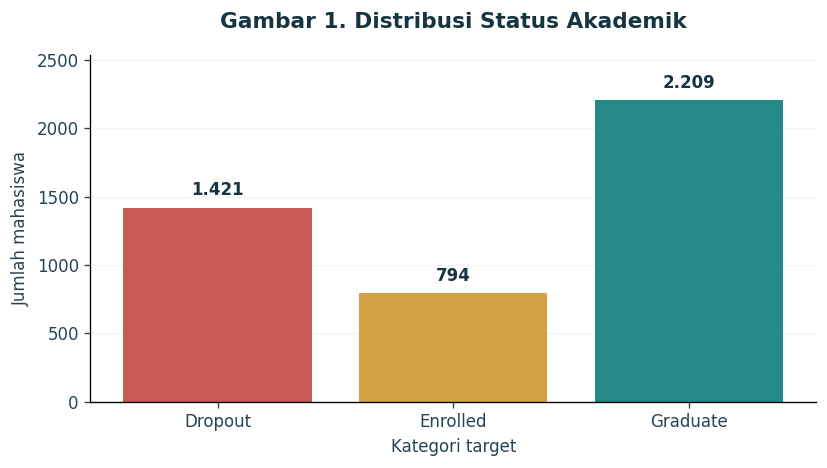

In [ ]:
distribution = df['Target'].value_counts().reindex(LABELS).rename('Jumlah').to_frame()
distribution['Persentase (%)'] = (distribution['Jumlah'] / len(df) * 100).round(2)
show_table(distribution.rename_axis('Kategori').reset_index(), 'Tabel 4. Distribusi target', {'Persentase (%)': '{:.2f}'})
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(distribution.index, distribution['Jumlah'], color=['#c55b52', '#d2a344', '#268a88'])
ax.bar_label(bars, labels=[f'{v:,}'.replace(',', '.') for v in distribution['Jumlah']], padding=5, fontweight='bold')
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.15)
ax.set(title='Gambar 1. Distribusi Status Akademik', xlabel='Kategori target', ylabel='Jumlah mahasiswa')
ax.set_ylim(0, distribution['Jumlah'].max()*1.15)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

Kelas tidak seimbang. Karena Graduate paling banyak, prediksi yang selalu memilih
Graduate sudah dapat menghasilkan akurasi mendekati 50%. Oleh sebab itu, akurasi
perlu dibaca bersama kinerja setiap kelas dan pembanding sederhana.

### 4.5 Penentuan Fitur dan Target
`Target` hanya menjadi y dan tidak masuk fitur X. Tabel berikut mendokumentasikan
seluruh fitur yang benar-benar dipakai dan perlakuannya dalam pipeline.

In [ ]:
categorical_cols = [
    'Marital status', 'Application mode', 'Course', 'Daytime/evening attendance',
    'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs',
    'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International'
]
X = df.drop(columns='Target').copy()
y = df['Target'].astype(str).copy()
numeric_cols = [c for c in X.columns if c not in categorical_cols]
for c in categorical_cols:
    X[c] = X[c].astype(str)
assert len(categorical_cols) + len(numeric_cols) == 36
assert 'Target' not in X.columns
dictionary = pd.DataFrame({
    'Variabel': X.columns,
    'Perlakuan': ['Kategori → one-hot' if c in categorical_cols else 'Numerik → dipertahankan' for c in X.columns]
})
show_table(dictionary, 'Tabel 5. Daftar lengkap 36 fitur dan perlakuannya — klik untuk membuka', collapsible=True)
print('Fitur kategori:', len(categorical_cols), '| Fitur numerik:', len(numeric_cols))

Fitur kategori: 17 | Fitur numerik: 19


Variabel,Perlakuan
Marital status,Kategori → one-hot
Application mode,Kategori → one-hot
Application order,Numerik → dipertahankan
Course,Kategori → one-hot
Daytime/evening attendance,Kategori → one-hot
Previous qualification,Kategori → one-hot
Previous qualification (grade),Numerik → dipertahankan
Nacionality,Kategori → one-hot
Mother's qualification,Kategori → one-hot
Father's qualification,Kategori → one-hot


### 4.6 Pembagian Data
Sebanyak 80% digunakan untuk latihan dan 20% untuk pengujian. `stratify=y` mempertahankan
proporsi kelas secara mendekati. `random_state=42` membantu mengulangi pembagian yang sama.
Pembagian ini adalah evaluasi acak internal, bukan pengujian terhadap angkatan masa depan.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_test.index)
split_table = pd.DataFrame({
    'Data latih': y_train.value_counts().reindex(LABELS),
    'Data uji': y_test.value_counts().reindex(LABELS)
})
split_table.loc['Total'] = split_table.sum()
show_table(split_table.rename_axis('Kategori').reset_index(), 'Tabel 6. Pembagian data latih dan data uji')

Kategori,Data latih,Data uji
Dropout,1137,284
Enrolled,635,159
Graduate,1767,442
Total,3539,885


### 4.7 Pipeline dan Validasi Silang
One-hot encoding mempelajari kategori dari data latih saja. Kategori baru pada data uji
ditangani oleh `handle_unknown='ignore'`. Validasi silang stratified lima lipatan digunakan
untuk melihat variasi kinerja internal. Pipeline dipasang ulang pada tiap lipatan.
Data uji akhir tidak digunakan untuk memilih parameter atau mengubah model.

In [ ]:
preprocessor = ColumnTransformer([
    ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols),
    ('numerik', 'passthrough', numeric_cols)
])
model = Pipeline([
    ('preprocess', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=2,
        class_weight='balanced', random_state=SEED, n_jobs=2
    ))
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_validate(model, X_train, y_train, cv=cv,
                           scoring={'accuracy':'accuracy', 'macro_f1':'f1_macro'}, n_jobs=1)
cv_table = pd.DataFrame({
    'Lipatan': range(1, 6),
    'Akurasi': cv_scores['test_accuracy'],
    'Macro F1': cv_scores['test_macro_f1']
})
cv_table['Lipatan'] = cv_table['Lipatan'].astype(str)
cv_summary = cv_table[['Akurasi', 'Macro F1']].agg(['mean', 'std']).reset_index()
cv_summary = cv_summary.rename(columns={'index': 'Lipatan'})
cv_summary['Lipatan'] = ['Rata-rata', 'Simpangan baku']
show_table(pd.concat([cv_table, cv_summary], ignore_index=True),
           'Tabel 7. Validasi silang lima lipatan pada data latih',
           {'Akurasi': '{:.4f}', 'Macro F1': '{:.4f}'})
print('Simpangan baku antar-lipatan bukan interval kepercayaan.')

Simpangan baku antar-lipatan bukan interval kepercayaan.


Lipatan,Akurasi,Macro F1
1,0.7754,0.7344
2,0.7782,0.7289
3,0.7881,0.7436
4,0.7415,0.6832
5,0.7412,0.6924
Rata-rata,0.7649,0.7165
Simpangan baku,0.0220,0.0269


## 5. Hasil dan Pembahasan

### 5.1 Evaluasi Model

| Metrik | Arti |
|---|---|
| Akurasi | Proporsi seluruh prediksi yang benar |
| Precision kelas | Dari prediksi kelas itu, berapa bagian yang benar |
| Recall kelas | Dari anggota kelas sebenarnya, berapa bagian yang terdeteksi |
| F1-score | Rata-rata harmonik precision dan recall |
| Macro F1 | Rata-rata F1 ketiga kelas dengan bobot yang sama |

Pembanding `DummyClassifier` selalu memprediksi kelas yang paling banyak di data latih.

In [ ]:
model.fit(X_train, y_train)
pred = model.predict(X_test)
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

def evaluate(actual, predicted):
    return {
        'Akurasi': accuracy_score(actual, predicted),
        'Precision macro': precision_score(actual, predicted, average='macro', zero_division=0),
        'Recall macro': recall_score(actual, predicted, average='macro', zero_division=0),
        'Macro F1': f1_score(actual, predicted, average='macro', zero_division=0)
    }
results = pd.DataFrame({
    'Tebakan kelas mayoritas': evaluate(y_test, pred_dummy),
    'Random Forest': evaluate(y_test, pred)
}).T
score_view = results.copy()
score_view['Akurasi (%)'] = score_view.pop('Akurasi') * 100
score_view = score_view[['Akurasi (%)', 'Precision macro', 'Recall macro', 'Macro F1']]
show_table(score_view.rename_axis('Model').reset_index(),
           'Tabel 8. Perbandingan kinerja pada data uji',
           {'Akurasi (%)': '{:.2f}', 'Precision macro': '{:.4f}',
            'Recall macro': '{:.4f}', 'Macro F1': '{:.4f}'})
report = pd.DataFrame(classification_report(y_test, pred, labels=LABELS,
                       output_dict=True, zero_division=0)).T
class_report = report.loc[LABELS, ['precision', 'recall', 'f1-score', 'support']].copy()
class_report['support'] = class_report['support'].astype(int)
class_report = class_report.rename(columns={'precision':'Precision', 'recall':'Recall',
                                             'f1-score':'F1-score', 'support':'Jumlah data'})
show_table(class_report.rename_axis('Kategori').reset_index(),
           'Tabel 9. Evaluasi masing-masing kategori',
           {'Precision':'{:.4f}', 'Recall':'{:.4f}', 'F1-score':'{:.4f}'})

Model,Akurasi (%),Precision macro,Recall macro,Macro F1
Tebakan kelas mayoritas,49.94,0.1665,0.3333,0.2221
Random Forest,74.80,0.7046,0.7045,0.7003


Kategori,Precision,Recall,F1-score,Jumlah data
Dropout,0.8182,0.6972,0.7529,284
Enrolled,0.4461,0.5723,0.5014,159
Graduate,0.8497,0.8439,0.8468,442


### 5.2 Confusion Matrix

Baris menunjukkan status sebenarnya dan kolom menunjukkan prediksi model. Angka diagonal adalah prediksi benar.

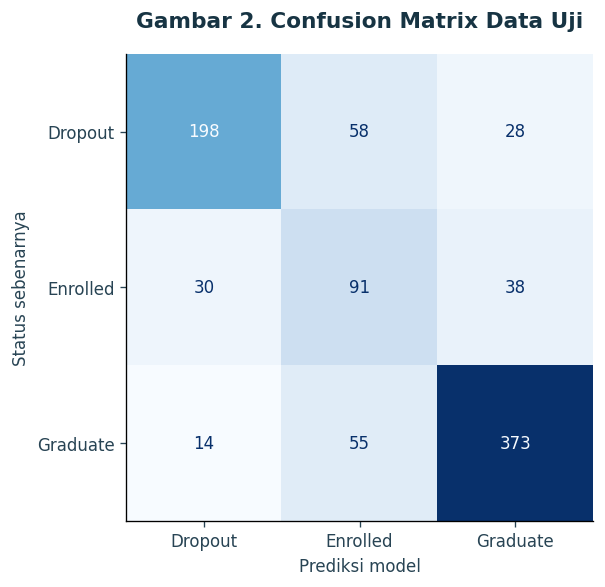

In [ ]:
cm = confusion_matrix(y_test, pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set(title='Gambar 2. Confusion Matrix Data Uji', xlabel='Prediksi model', ylabel='Status sebenarnya')
plt.tight_layout()
plt.show()

### 5.3 Interpretasi Hasil
Diagonal confusion matrix adalah prediksi benar; sel di luar diagonal adalah kesalahan.
Narasi berikut dihitung dari keluaran model sehingga mengikuti hasil setiap eksekusi.

In [ ]:
rf_metrics = results.loc['Random Forest']
base_metrics = results.loc['Tebakan kelas mayoritas']
weakest = report.loc[LABELS, 'f1-score'].idxmin()
dropout_idx = LABELS.index('Dropout')
missed_dropout = int(cm[dropout_idx].sum() - cm[dropout_idx, dropout_idx])
wrong_dropout = int(cm[:, dropout_idx].sum() - cm[dropout_idx, dropout_idx])
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
i, j = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
# Ringkasan visual mengikuti hasil model setiap kali notebook dijalankan.
display(HTML(f'''
<table style="border-collapse:collapse;width:100%;max-width:760px;font-family:Arial;margin:16px 0;">
<tr>
<td style="padding:18px;background:#eaf5f3;border-right:5px solid white;">
<span style="font-size:12px;color:#356260;">AKURASI DATA UJI</span><br>
<strong style="font-size:27px;color:#176b67;">{rf_metrics['Akurasi']:.2%}</strong></td>
<td style="padding:18px;background:#edf3f7;border-right:5px solid white;">
<span style="font-size:12px;color:#3d6073;">MACRO F1</span><br>
<strong style="font-size:27px;color:#234d63;">{rf_metrics['Macro F1']:.4f}</strong></td>
<td style="padding:18px;background:#f4f5f6;">
<span style="font-size:12px;color:#5a6870;">MAHASISWA DATA UJI</span><br>
<strong style="font-size:27px;color:#334650;">{len(y_test)}</strong></td>
</tr></table>
'''))
display(Markdown(f'''
Pada **{len(y_test)} mahasiswa dalam data uji**, Random Forest memperoleh akurasi
**{rf_metrics['Akurasi']:.2%}** dan macro F1 **{rf_metrics['Macro F1']:.4f}**.
Pembanding kelas mayoritas memperoleh akurasi **{base_metrics['Akurasi']:.2%}** dan
macro F1 **{base_metrics['Macro F1']:.4f}**. Selisih akurasi model terhadap pembanding
adalah **{100*(rf_metrics['Akurasi']-base_metrics['Akurasi']):.2f} poin persentase**.

Kelas dengan F1 terendah adalah **{weakest}**, dengan F1 **{report.loc[weakest, 'f1-score']:.4f}**.
Kesalahan antarkelas paling banyak adalah **{LABELS[i]} diprediksi {LABELS[j]}**
sebanyak **{int(cm[i,j])} mahasiswa**.

Recall Dropout adalah **{report.loc['Dropout', 'recall']:.2%}**:
**{missed_dropout} mahasiswa berlabel Dropout tidak terdeteksi sebagai Dropout**.
Sebaliknya, **{wrong_dropout} mahasiswa dari kelas lain diprediksi Dropout**.
Kesalahan ini perlu diperhitungkan ketika menentukan prioritas pendampingan.
'''))

AKURASI DATA UJI 74.80%,MACRO F1 0.7003,MAHASISWA DATA UJI 885



Pada **885 mahasiswa dalam data uji**, Random Forest memperoleh akurasi
**74.80%** dan macro F1 **0.7003**.
Pembanding kelas mayoritas memperoleh akurasi **49.94%** dan
macro F1 **0.2221**. Selisih akurasi model terhadap pembanding
adalah **24.86 poin persentase**.

Kelas dengan F1 terendah adalah **Enrolled**, dengan F1 **0.5014**.
Kesalahan antarkelas paling banyak adalah **Dropout diprediksi Enrolled**
sebanyak **58 mahasiswa**.

Recall Dropout adalah **69.72%**:
**86 mahasiswa berlabel Dropout tidak terdeteksi sebagai Dropout**.
Sebaliknya, **44 mahasiswa dari kelas lain diprediksi Dropout**.
Kesalahan ini perlu diperhitungkan ketika menentukan prioritas pendampingan.


### 5.4 Contoh Prediksi
Baris berikut benar-benar berasal dari data uji yang belum dilihat saat pelatihan.
Nomor baris adalah indeks data, bukan identitas mahasiswa. Ini ilustrasi penerapan,
bukan bukti tambahan di luar evaluasi pada bagian sebelumnya.

In [ ]:
examples = pd.DataFrame({
    'Nomor baris dataset': X_test.index[:10],
    'Status sebenarnya': y_test.iloc[:10].to_numpy(),
    'Prediksi': pred[:10]
})
examples['Benar'] = examples['Status sebenarnya'].eq(examples['Prediksi'])
show_table(examples, 'Tabel 10. Contoh prediksi pada sepuluh observasi data uji')

# Untuk mahasiswa baru, siapkan DataFrame dengan nama dan definisi kolom yang sama.
# hasil_baru = model.predict(data_mahasiswa_baru[X.columns])

Nomor baris dataset,Status sebenarnya,Prediksi,Benar
1853,Graduate,Graduate,True
2399,Graduate,Graduate,True
510,Enrolled,Dropout,False
242,Graduate,Graduate,True
3392,Graduate,Graduate,True
1787,Graduate,Graduate,True
1158,Graduate,Graduate,True
260,Graduate,Graduate,True
1852,Graduate,Enrolled,False
1191,Graduate,Graduate,True


## 6. Manfaat, Keterbatasan, dan Kesimpulan

### 6.1 Manfaat dan Keterbatasan

**Manfaat potensial:** membantu menyusun prioritas peninjauan akademik, mendukung
pendampingan yang lebih terarah, dan memberi contoh pemanfaatan data pendidikan.
Peningkatan kelulusan atau penurunan dropout belum diukur dalam eksperimen ini;
manfaat tersebut memerlukan evaluasi intervensi nyata.

**Keterbatasan:**
- Dataset berasal dari satu konteks institusi di Portugal; generalisasi ke Indonesia belum diuji.
- Prediksi memakai informasi semester 1–2. Tanggal dropout dan pembaruan status administratif
  tidak tersedia, sehingga kebocoran waktu tidak dapat disingkirkan hanya dengan pembagian acak.
- Enrolled merupakan status pada batas observasi, bukan kepastian hasil akhir mahasiswa.
- Ketimpangan kelas dan informasi orang tua yang tidak diketahui dapat memengaruhi kinerja.
- Hubungan prediktif tidak membuktikan sebab-akibat. Fitur demografi memerlukan pemeriksaan
  keadilan antarkelompok sebelum model dipakai untuk layanan mahasiswa.
- Satu pembagian data uji dan satu keluarga model belum cukup untuk menyatakan algoritma terbaik.

Pengembangan berikutnya dapat memakai data angkatan berbeda, mendokumentasikan waktu setiap
fitur, membandingkan algoritma dengan validasi yang sama, serta menilai manfaat pendampingan.

### 6.2 Kesimpulan
Kesimpulan numerik di bawah diperbarui otomatis dari hasil evaluasi.

In [ ]:
comparison = ('lebih tinggi' if rf_metrics['Macro F1'] > base_metrics['Macro F1'] else 'tidak lebih tinggi')
display(Markdown(f'''
Random Forest berhasil diterapkan untuk mengklasifikasikan status akademik ke dalam
Dropout, Enrolled, dan Graduate. Pada pembagian data ini, akurasinya **{rf_metrics['Akurasi']:.2%}**
dan macro F1 **{rf_metrics['Macro F1']:.4f}**. Macro F1 model {comparison} daripada
pembanding kelas mayoritas. Kinerja kelas **{weakest}** masih perlu diperhatikan.

Eksperimen menunjukkan kemampuan klasifikasi pada dataset yang digunakan. Hasilnya
belum membuktikan bahwa model siap menjadi sistem peringatan dini atau dapat menurunkan
angka putus studi. Untuk penerapan, diperlukan validasi waktu, data institusi sasaran,
dan peninjauan manusia atas rekomendasi model.
'''))


Random Forest berhasil diterapkan untuk mengklasifikasikan status akademik ke dalam
Dropout, Enrolled, dan Graduate. Pada pembagian data ini, akurasinya **74.80%**
dan macro F1 **0.7003**. Macro F1 model lebih tinggi daripada
pembanding kelas mayoritas. Kinerja kelas **Enrolled** masih perlu diperhatikan.

Eksperimen menunjukkan kemampuan klasifikasi pada dataset yang digunakan. Hasilnya
belum membuktikan bahwa model siap menjadi sistem peringatan dini atau dapat menurunkan
angka putus studi. Untuk penerapan, diperlukan validasi waktu, data institusi sasaran,
dan peninjauan manusia atas rekomendasi model.


## 7. Daftar Referensi

1. Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021).
   *Predict Students’ Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository.
   https://doi.org/10.24432/C5MC89. Lisensi: CC BY 4.0. Digunakan untuk dataset dan kamus variabel.
2. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022).
   Predicting Student Dropout and Academic Success. *Data, 7*(11), 146.
   https://doi.org/10.3390/data7110146. Digunakan untuk konteks masalah dan definisi status.
3. Scikit-learn developers. *RandomForestClassifier*.
   https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html.
   Digunakan untuk metode dan parameter model.
4. Scikit-learn developers. *Common pitfalls and recommended practices*.
   https://scikit-learn.org/stable/common_pitfalls.html.
   Digunakan untuk pencegahan kebocoran data dalam preprocessing.

Sumber diakses pada **18 Oktober 2026**. Semua tabel evaluasi dalam notebook merupakan
hasil perhitungan kode pada eksperimen ini, bukan kutipan angka kinerja dari referensi.